# GP-Hedge on BBOB: how much of the switching headroom does an online portfolio recover?

## Description

*Written 2026-11-10 ~18:30, before the first run. Baseline for the learned selector (issue #11, PR #12).*

**Question.** `bbob_switching` (notebook 04) found large luck-corrected headroom for switching
acquisition functions within a run on noise-free BBOB. The privileged rollout controller beats the tuned
static arm B\* by +59% / +19% (GP, d = 2 / 5) and +66% / +29% (PFN). A controller that uses task
knowledge is a ceiling, not a method.

The standard non-learned way to switch is GP-Hedge (Brochu, Hoffman & de Freitas 2011): an online
portfolio over acquisition functions, rewarded by the updated posterior mean at each arm's nominee.
*How much of the headroom does GP-Hedge recover, and is it better than the tuned static arm at all?*
The answer sets the bar a learned selector has to clear: max(B\*, GP-Hedge).

**Setup.** Everything is identical to the `bbob_switching` confirm sweeps:
- split 1: BBOB f1–f24, instances 2–5, 2 repetitions, i.e. 192 tasks per d;
- d ∈ {2, 5}, n_init = 2d, T = 10d;
- arms ei, pi0.01, ucb0.9, ucb0.99, mes, mean;
- the same candidate sets (CRN keyed by task, step and replicate), the same rank-transformed surrogates;
- f − f_opt, log10(regret + 1e-8).

Each hedge run therefore pairs task by task with:
- the static arms and B\* from `results/bbob_switching/confirm_20261022-145708` (GP, B\* = ucb0.9) and
  `confirm_20261023-075829` (PFN, B\* = ucb0.99);
- the privileged controller and the equal-arms null in the same snapshots.

GP-Hedge, as implemented (`bo/runner.py::run_hedge`, Algorithm 2 of the paper):
- at every step, each arm nominates its maximiser on the shared candidate set;
- one nominee is evaluated, drawn with p ∝ exp(η · g);
- after the posterior update, every arm's gain g is increased by the reward −μ(its nominee), with μ on
  the [0, 1] scale: Φ(μ_z) for the GP, the rank-scale mean for the PFN.

The paper gives no η. Members: η = 1.0 (scikit-optimize's default) and η = 10. Sweep: surrogate ∈ {gp,
pfn} × d ∈ {2, 5} × η ∈ {1, 10}, 8 members, on CPU. A timing probe (24 tasks, d = 5) took 99 s (GP)
and 373 s (PFN).

**What to look for.**
- **Primary:** per surrogate and d, the paired gain of hedge (η = 1) over B\*, as 1 − geometric-mean
  ratio of final regrets with a 95% bootstrap CI over tasks (`analysis.bo.paired_gain`, as in notebook 04).
  Next to it: the privileged gain (ceiling) and the null's gain (noise floor).
- **Secondary:**
  - hedge vs ei (the untuned default, the fair comparison for a user who did not tune B\*);
  - η = 10 vs η = 1;
  - per BBOB function group;
  - arm probabilities over the run (which arms Hedge converges to, and whether that is B\*).

**Reading (pre-registered; this is a baseline measurement, not a gate).**
- CI above 0: hedge recovers headroom. Report the share of the privileged gain, gain_hedge / gain_priv.
- CI below 0: hedge loses to the tuned static arm. The learned selector's bar is then B\*.
- CI includes 0: no detectable difference at n = 192. The null's CI width is the reference for what is
  detectable.
- A **check that the setup is right:** a hedge run whose probabilities stay uniform (|p − 1/6| < 0.02 at
  the last step in more than 90% of tasks) means the rewards carry no signal at this η. That would be
  flagged and investigated before reading the gains.

**Limits.**
- Noise-free BBOB only; the noisy setting (#9) is not covered.
- One seed, one nuisance stream.
- The GP-Hedge reward is computed on each surrogate's own transformed scale. The PFN variant is our
  adaptation, not the paper's method; the GP variant is the paper's.
- B\* was selected on split 0, so it is a tuned baseline that hedge does not get.
- The hedge runs use the CPU, and the confirm sweeps used ulysses' GPU. Tasks and initial designs are the same,
  but the arithmetic is not bit-identical, so the pairing is by task, not by trajectory.


**Follow-up (registered 2026-11-10 21:20, after reading the primary result and before launching it).**
The primary run (§0) shows Hedge choosing the `mean` arm in 44–90% of steps. The cause is in the reward:
−μ(nominee) is largest for the nominee that minimises μ, which is exactly the `mean` arm's nominee. In the
primary run `mean` earned the step's top reward in 46–85% of steps, and its reward was on average 0.002–0.02
below the step's best, against 0.06–0.37 for every other arm. So Hedge measures "which arm proposes the point
with the lowest posterior mean", which the exploitation arm wins by construction. Brochu et al.'s portfolio
(EI, PI, UCB) contains no such arm.

- **Test:** `experiment=bbob_hedge_nomean`, the same 8-member sweep with arms {ei, pi0.01, ucb0.9, ucb0.99,
  mes}. Only the arm set changes.
- **Primary of the follow-up:** per surrogate, d and η, the paired gain of hedge-without-mean over B\*, read
  with the rules above.
- **The fix works if:**
  - at η = 1, no (surrogate, d) cell is significantly worse than B\* (CI upper bound < 0). In the primary
    run, 2 of the 4 were (gp d = 5, pfn d = 5);
  - no single arm is chosen in more than 60% of steps of any member.
- **If it does not:** the remaining reward bias, toward low-μ nominees of the exploitative arms (pi0.01,
  ucb0.9), is the explanation to test next, e.g. rewarding the realised improvement instead of −μ.
  That would be a further deviation from the paper.
- **Either way,** the GP-Hedge baseline for later comparisons is the paper's portfolio, i.e. the variant
  without `mean`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.bo import final, mde_gain, paired_gain, regrets

HEDGE = 'results/bbob_hedge/pilot_20261110-180520'
CONFIRM = {"gp": "results/bbob_switching/confirm_20261022-145708", "pfn": "results/bbob_switching/confirm_20261023-075829"}
BSTAR = {"gp": "ucb0.9", "pfn": "ucb0.99"}  # notebook 04, selected on split 0 (same B* at d = 2 and 5)
ARMS = ["ei", "pi0.01", "ucb0.9", "ucb0.99", "mes", "mean"]
GROUPS = {"separable": range(1, 6), "low cond.": range(6, 10), "high cond.": range(10, 15),
          "multimodal": range(15, 20), "weak structure": range(20, 25)}
GROUP_OF = {f: g for g, fs in GROUPS.items() for f in fs}
plt.rcParams.update({"figure.dpi": 85, "axes.spines.top": False, "axes.spines.right": False})


def column(snap, key):
    return snap.runs[key] if key in snap.runs else pd.Series(snap.constants[key], index=snap.runs.index)


def load(snap, rename_hedge=False):
    runs = snap.runs.assign(d=column(snap, "task.d"), surrogate=column(snap, "task.surrogate")).set_index("member")
    best = snap.table("best")
    if rename_hedge:
        eta = column(snap, "task.hedge_eta").set_axis(snap.runs.member)
        best = best.assign(arm=lambda b: b.arm + "_eta" + b.member.map(eta).astype(float).map("{:g}".format))
    reg = regrets(best, snap.table("fstar"), runs["d"], eps=1e-8)
    ids = snap.table("tasks").drop_duplicates(["member", "seed"]).set_index(["member", "seed"])[["fid"]]
    return reg.join(ids, on=["member", "seed"]).assign(surrogate=lambda x: x.member.map(runs.surrogate))


hsnap = load_snapshot(HEDGE)
show_header(hsnap)
H = load(hsnap, rename_hedge=True)
REG = {s: pd.concat([load(load_snapshot(p)), H[H.surrogate == s]], ignore_index=True) for s, p in CONFIRM.items()}
FIN = {s: final(r).merge(r.drop_duplicates(["d", "arm", "seed"])[["d", "arm", "seed", "fid"]], on=["d", "arm", "seed"])
       for s, r in REG.items()}
for s, f in FIN.items():
    print(s, "tasks per (d, arm):", sorted(f.groupby(["d", "arm"]).size().unique()), "| arms:", sorted(f.arm.unique()))

## How it was run

```bash
just sweep detached pilot experiment=bbob_hedge task.surrogate=gp,pfn task.d=2,5 task.hedge_eta=1.0,10.0
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261110-180520` |
| commit | `d3036429e9f9` (tag `sweep/bbob_hedge/pilot_20261110-180520`) |
| backend / host | detached / ruhkopf-XPS-15-9510 |
| ran | 2026-11-10T18:05:21 → 2026-11-10T21:06:39 |
| members | 8: 8 done |
| compute | 3.0 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/bbob_hedge.yaml`):

```yaml
# @package _global_
# GP-Hedge on BBOB (issue #11 baseline): how much of the switching headroom does an online portfolio recover?
# Pre-registration: notebooks/05_2026-11-10_bbob_hedge.ipynb. Same tasks, arms, candidates and budget as the
# bbob_switching confirm sweeps (split 1, 192 tasks per d), so every hedge run pairs task by task with the
# static arms and the privileged controller there.
# Sweep: task.surrogate=gp,pfn task.d=2,5 task.hedge_eta=1.0,10.0
defaults:
  - override /task: bo

task:
  benchmark: bbob
  surrogate: gp
  split: 1
  method: hedge
  arms: [ei, pi0.01, ucb0.9, ucb0.99, mes, mean]
  base: ei
  null_reference: false
  eps: 1.0e-8
  hedge_eta: 1.0
  device: cpu
```

**Varying** (8 configurations):

| task.d | task.hedge_eta | task.surrogate |
|---|---|---|
| 2 | 1.0 | gp |
| 2 | 10.0 | gp |
| 5 | 1.0 | gp |
| 5 | 10.0 | gp |
| 2 | 1.0 | pfn |
| 2 | 10.0 | pfn |
| 5 | 1.0 | pfn |
| 5 | 10.0 | pfn |

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  alpha: alpha_pes_large
  arms: '["ei", "pi0.01", "ucb0.9", "ucb0.99", "mes", "mean"]'
  base: ei
  bbob.fids: '[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
    20, 21, 22, 23, 24]'
  bbob.instances_by_split.0: '[1]'
  bbob.instances_by_split.1: '[2, 3, 4, 5]'
  bbob.instances_by_split.2: '[6]'
  bbob.reps: 2
  benchmark: bbob
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 512
  device: cpu
  eps: 1.0e-08
  gp_fit_iters: 100
  method: hedge
  n_init_per_d: 2
  n_rollouts: 8
  n_tasks: 100
  name: bo
  null_k: 6
  null_reference: false
  pfn: pfn_large
  random_search: true
  segment_per_d: 2
  split: 1
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  task_offset: 0
  tf32: false
```

gp tasks per (d, arm): [np.int64(192)] | arms: ['ctrl:equal_arms', 'ctrl:privileged', 'ei', 'hedge_eta1', 'hedge_eta10', 'mean', 'mes', 'pi0.01', 'random', 'ucb0.9', 'ucb0.99', 'ucb0.9@0']
pfn tasks per (d, arm): [np.int64(192)] | arms: ['ctrl:equal_arms', 'ctrl:privileged', 'ei', 'hedge_eta1', 'hedge_eta10', 'mean', 'mes', 'pi0.01', 'random', 'ucb0.9', 'ucb0.99', 'ucb0.99@0']


## Results

### 0. Is the setup right? Hedge's probabilities over the run

Mean probability of each arm per step (over tasks), and the share of tasks whose last-step probabilities
are still uniform (all within 0.02 of 1/6; the pre-registered check that the rewards carry signal).

,surrogate,d,eta,share uniform at the end,chosen ei,chosen pi0.01,chosen ucb0.9,chosen ucb0.99,chosen mes,chosen mean
0,gp,2,1.0,0.0,0.090,0.194,0.141,0.080,0.057,0.439
1,gp,2,10.0,0.0,0.026,0.154,0.043,0.017,0.017,0.743
2,gp,5,1.0,0.0,0.048,0.096,0.121,0.046,0.038,0.651
3,gp,5,10.0,0.0,0.021,0.052,0.034,0.013,0.013,0.867
4,pfn,2,1.0,0.0,0.136,0.171,0.108,0.050,0.061,0.473
5,pfn,2,10.0,0.0,0.040,0.085,0.017,0.013,0.017,0.827
6,pfn,5,1.0,0.0,0.093,0.070,0.177,0.030,0.049,0.581
7,pfn,5,10.0,0.0,0.036,0.024,0.022,0.006,0.011,0.902


flag (uniform in > 90% of tasks): []


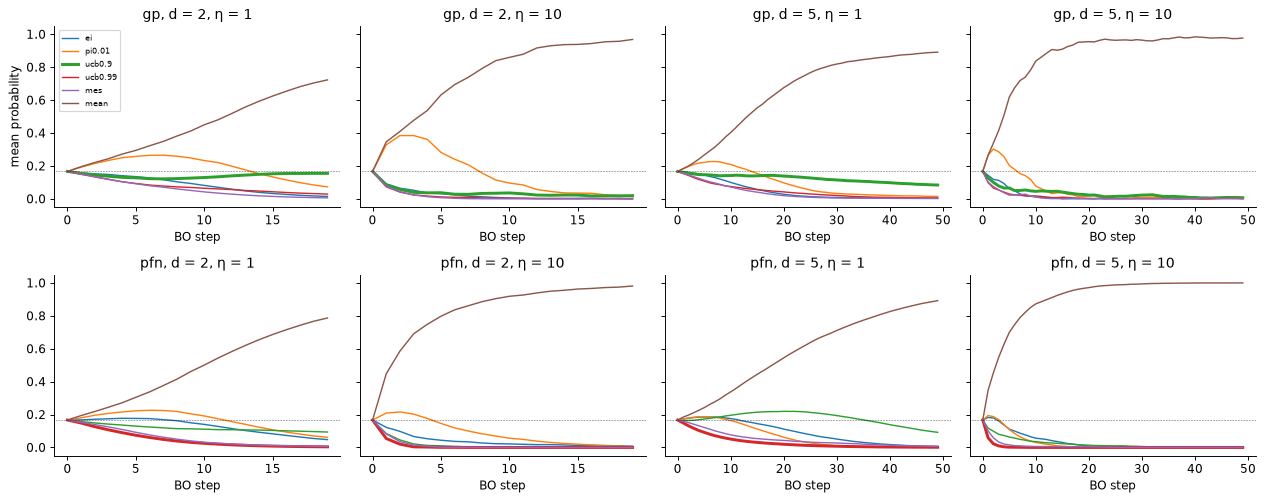

In [ ]:
HT = hsnap.table("hedge").merge(hsnap.runs[["member"]].assign(
    d=column(hsnap, "task.d").values, surrogate=column(hsnap, "task.surrogate").values,
    eta=column(hsnap, "task.hedge_eta").astype(float).values), on="member")
members = HT.groupby(["surrogate", "d", "eta"]).size().index
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
rows = []
for ax, (s, d, eta) in zip(axes.ravel(), members):
    h = HT[(HT.surrogate == s) & (HT.d == d) & (HT.eta == eta)]
    for k, a in enumerate(ARMS):
        m = h.groupby("step")[f"p/{a}"].mean()
        ax.plot(m.index, m, color=f"C{k}", lw=2.5 if a == BSTAR[s] else 1.2, label=a)
    ax.axhline(1 / 6, color="k", lw=0.5, ls=":")
    ax.set(title=f"{s}, d = {d}, η = {eta:g}", xlabel="BO step")
    last = h[h.step == h.step.max()]
    P = last[[f"p/{a}" for a in ARMS]].to_numpy()
    rows.append({"surrogate": s, "d": d, "eta": eta, "share uniform at the end": float((np.abs(P - 1 / 6) < 0.02).all(1).mean()),
                 **{f"chosen {a}": float((h.chosen == a).mean()) for a in ARMS}})
axes[0, 0].set_ylabel("mean probability")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
CHECK = pd.DataFrame(rows)
display(CHECK.round(3))
print("flag (uniform in > 90% of tasks):", CHECK[CHECK["share uniform at the end"] > 0.9][["surrogate", "d", "eta"]].to_dict("records"))

### 1. Primary: gain over the tuned static arm B\*, next to the ceiling and the null

1 − geometric-mean ratio of final regrets, paired over the 192 tasks of split 1, 95% bootstrap CI. A
positive gain means fewer regret than B\*. `privileged` (task knowledge) is the ceiling and the equal-arms
null is the noise floor, both from notebook 04's confirm sweeps on the same tasks. `mde80` is the smallest gain
detectable with 80% power at this task-to-task spread.

In [ ]:
rows = []
for s, f in FIN.items():
    b = BSTAR[s]
    for d in sorted(f.d.unique()):
        present = set(f.loc[f.d == d, "arm"])
        for a, ref in [("hedge_eta1", b), ("hedge_eta10", b), ("ctrl:privileged", b), ("ctrl:equal_arms", f"{b}@0"),
                       ("hedge_eta1", "ei"), ("hedge_eta10", "ei")]:
            if a in present and ref in present:
                rows.append({"surrogate": s, **paired_gain(f, d, a, ref)})
PRIMARY = pd.DataFrame(rows)
PRIMARY["mde80"] = [mde_gain(sd, n) for sd, n in zip(PRIMARY.sd_log_ratio, PRIMARY.n, strict=True)]
PRIMARY[["surrogate", "d", "a", "b", "n", "gain", "gain_lo", "gain_hi", "frac_a_better", "mde80"]].round(3)

,surrogate,d,a,b,n,gain,gain_lo,gain_hi,frac_a_better,mde80
0,gp,2,hedge_eta1,ucb0.9,192,-0.034,-0.301,0.179,0.427,0.281
1,gp,2,hedge_eta10,ucb0.9,192,0.058,-0.217,0.273,0.453,0.311
2,gp,2,ctrl:privileged,ucb0.9,192,0.586,0.459,0.688,0.615,0.327
3,gp,2,ctrl:equal_arms,ucb0.9@0,192,-0.050,-0.435,0.220,0.406,0.351
4,gp,2,hedge_eta1,ei,192,0.420,0.226,0.569,0.552,0.342
5,gp,2,hedge_eta10,ei,192,0.472,0.272,0.623,0.557,0.377
6,gp,5,hedge_eta1,ucb0.9,192,-0.297,-0.776,-0.010,0.464,0.328
7,gp,5,hedge_eta10,ucb0.9,192,-0.083,-0.462,0.146,0.495,0.316
8,gp,5,ctrl:privileged,ucb0.9,192,0.188,0.031,0.319,0.568,0.224
9,gp,5,ctrl:equal_arms,ucb0.9@0,192,-0.057,-0.209,0.077,0.464,0.173


In [ ]:
def share(s, d, eta):
    p = PRIMARY.set_index(["surrogate", "d", "a", "b"])
    try:
        return p.loc[(s, d, f"hedge_eta{eta}", BSTAR[s]), "gain"] / p.loc[(s, d, "ctrl:privileged", BSTAR[s]), "gain"]
    except KeyError:
        return np.nan


READ = []
for (s, d), g in PRIMARY[PRIMARY.b.isin(BSTAR.values())].groupby(["surrogate", "d"]):
    for eta in (1, 10):
        r = g[g.a == f"hedge_eta{eta}"]
        if r.empty:
            continue
        r = r.iloc[0]
        verdict = "recovers headroom" if r.gain_lo > 0 else ("worse than B*" if r.gain_hi < 0 else "no detectable difference")
        READ.append({"surrogate": s, "d": d, "eta": eta, "gain over B*": round(r.gain, 3),
                     "CI": f"[{r.gain_lo:+.3f}, {r.gain_hi:+.3f}]", "share of privileged gain": round(share(s, d, eta), 2),
                     "reading": verdict})
pd.DataFrame(READ)

,surrogate,d,eta,gain over B*,CI,share of privileged gain,reading
0,gp,2,1,-0.034,"[-0.301, +0.179]",-0.06,no detectable difference
1,gp,2,10,0.058,"[-0.217, +0.273]",0.10,no detectable difference
2,gp,5,1,-0.297,"[-0.776, -0.010]",-1.58,worse than B*
3,gp,5,10,-0.083,"[-0.462, +0.146]",-0.44,no detectable difference
4,pfn,2,1,-0.351,"[-1.067, +0.078]",-0.54,no detectable difference
5,pfn,2,10,-2.096,"[-4.330, -0.904]",-3.20,worse than B*
6,pfn,5,1,-0.379,"[-0.643, -0.169]",-1.30,worse than B*
7,pfn,5,10,-3.059,"[-5.450, -1.721]",-10.46,worse than B*


### 2. All arms and methods on split 1

Mean final log10 regret per method (lower is better), and the same per BBOB function group for η = 1.

In [ ]:
tab = pd.concat([f.assign(surrogate=s) for s, f in FIN.items()])
display(tab.pivot_table(index="arm", columns=["surrogate", "d"], values="log_regret").round(2))
tab["group"] = tab.fid.map(GROUP_OF)
keep = ["hedge_eta1", "ctrl:privileged", "ei"] + list(set(BSTAR.values()))
tab[tab.arm.isin(keep)].pivot_table(index=["group", "arm"], columns=["surrogate", "d"], values="log_regret").round(2)

surrogate          gp         pfn      
d                   2     5     2     5
arm                                    
ctrl:equal_arms  0.04  0.88  0.06  1.01
ctrl:privileged -0.30  0.82 -0.39  0.89
ei               0.34  1.29  0.11  1.18
hedge_eta1       0.10  1.03  0.20  1.18
hedge_eta10      0.06  0.95  0.56  1.65
mean             0.08  0.95  0.90  1.85
mes              0.29  1.23  0.11  1.10
pi0.01           0.23  1.27  0.19  1.18
random           1.25  2.29  1.25  2.29
ucb0.9           0.09  0.91 -0.07  1.07
ucb0.99          0.23  0.94  0.07  1.04
ucb0.99@0         NaN   NaN  0.05  1.00
ucb0.9@0         0.02  0.85   NaN   NaN

surrogate                         gp         pfn      
d                                  2     5     2     5
group          arm                                    
high cond.     ctrl:privileged  0.41  2.18  0.51  2.24
               ei               1.73  2.97  1.43  2.68
               hedge_eta1       0.81  2.41  1.01  2.64
               ucb0.9           1.00  2.22  0.88  2.54
               ucb0.99          1.25  2.43  1.33  2.57
low cond.      ctrl:privileged -0.23  1.20 -0.96  1.21
               ei               0.25  1.77 -0.26  1.32
               hedge_eta1       0.24  1.29  0.25  1.58
               ucb0.9           0.21  1.34 -0.27  1.28
               ucb0.99          0.20  1.28 -0.36  1.33
multimodal     ctrl:privileged  0.04  0.81 -0.05  0.87
               ei               0.35  1.02  0.33  0.96
               hedge_eta1       0.45  0.99  0.41  1.00
               ucb0.9           0.30  1.00  0.30  0.97
               ucb0.99          0.33  0.93  0.24  0.95
separable      ctrl:privileged -1.84 -0.63 -1.73 -0.55
               ei              -1.06 -0.14 -1.16  0.12
               hedge_eta1      -1.36 -0.24 -0.97 -0.13
               ucb0.9          -1.46 -0.63 -1.52 -0.26
               ucb0.99         -1.07 -0.56 -1.40 -0.34
weak structure ctrl:privileged  0.16  0.64  0.16  0.75
               ei               0.40  0.94  0.14  0.83
               hedge_eta1       0.39  0.74  0.34  0.89
               ucb0.9           0.40  0.73  0.23  0.84
               ucb0.99          0.43  0.68  0.47  0.76

### 3. Regret over the run

Mean log10 regret per step: hedge (η = 1, 10), B\*, ei and the privileged controller.

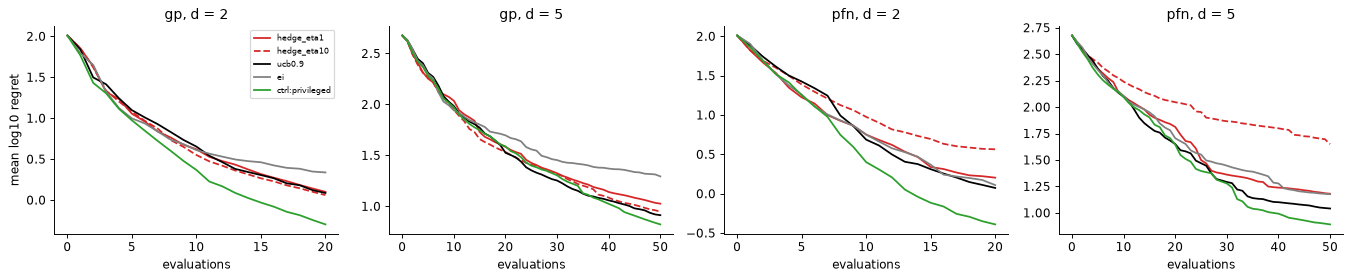

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (s, d) in zip(axes, [(s, d) for s in REG for d in sorted(REG[s].d.unique())]):
    r = REG[s][REG[s].d == d]
    for a, st in [("hedge_eta1", "C3-"), ("hedge_eta10", "C3--"), (BSTAR[s], "k-"), ("ei", "0.5"), ("ctrl:privileged", "C2-")]:
        m = r[r.arm == a].groupby("t").log_regret.mean()
        if len(m):
            ax.plot(m.index, m, st, label=a)
    ax.set(title=f"{s}, d = {d}", xlabel="evaluations")
axes[0].set_ylabel("mean log10 regret")
axes[0].legend(fontsize=7)
plt.tight_layout()